# Step 2 - Digital filters and the HFO simulator

This notebook illustrates step 2. The heavy lifting is done by the scripts:

1. `scripts/03_calibrate_simulator.py` fits the background spectrum and the spike sharpness on the real data;
2. `scripts/04_simulation_examples.py` draws example simulations;
3. `scripts/05_spike_filter_demo.py` shows why a filtered spike looks like an HFO.

Prerequisite: `.\run.ps1 run`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.signal import group_delay, sosfreqz, sos2tf

from epidetect import filters, plotting, qc, simulate
from epidetect.config import load_config
from epidetect.simulate import SimulationParams

plotting.apply_style()
%matplotlib inline
cfg = load_config()
results, figures = cfg["paths"]["results_dir"], cfg["paths"]["figures_dir"]
params = SimulationParams.from_config(cfg["simulation"])
FS = params.fs_hz
pd.set_option("display.width", 160)

## 1. The band-pass filter in the frequency domain (Bode plot)

Butterworth band-pass 250-500 Hz, design order 4 per edge (order 8). One forward pass has a gain of -3 dB at the cut-offs and a frequency-dependent group delay. `filtfilt` squares the gain (-6 dB at the cut-offs, twice the attenuation) and cancels the phase.

250 Hz: one-pass gain  -3.01 dB, filtfilt  -6.02 dB, one-pass group delay  6.31 ms
300 Hz: one-pass gain  -0.02 dB, filtfilt  -0.04 dB, one-pass group delay  4.21 ms
375 Hz: one-pass gain  -0.00 dB, filtfilt  -0.00 dB, one-pass group delay  3.12 ms
450 Hz: one-pass gain  -0.11 dB, filtfilt  -0.21 dB, one-pass group delay  3.81 ms
500 Hz: one-pass gain  -3.01 dB, filtfilt  -6.02 dB, one-pass group delay  4.46 ms


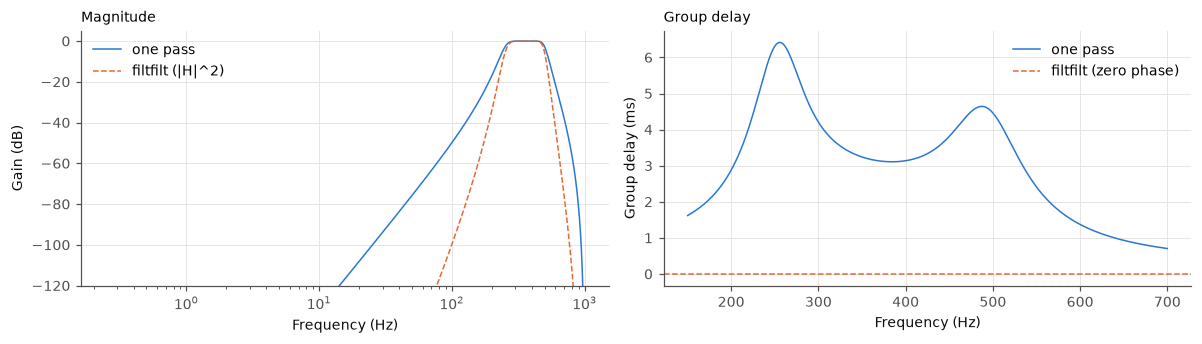

In [2]:
sos = filters.butter_bandpass_sos(FS, (250.0, 500.0), order=params.filter_order)
f, h = sosfreqz(sos, worN=4096, fs=FS)
b, a = sos2tf(sos)
f_gd, gd = group_delay((b, a), w=f[1:], fs=FS)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.2))
ax1.semilogx(f[1:], 20 * np.log10(np.abs(h[1:]) + 1e-12), color=plotting.SERIES[0], label="one pass")
ax1.semilogx(f[1:], 40 * np.log10(np.abs(h[1:]) + 1e-12), color=plotting.ACCENT, ls="--", label="filtfilt (|H|^2)")
ax1.set_ylim(-120, 5); ax1.set_xlabel("Frequency (Hz)"); ax1.set_ylabel("Gain (dB)")
ax1.set_title("Magnitude", loc="left"); ax1.legend()
band = (f_gd >= 150) & (f_gd <= 700)
ax2.plot(f_gd[band], gd[band] / FS * 1000, color=plotting.SERIES[0], label="one pass")
ax2.axhline(0, color=plotting.ACCENT, ls="--", label="filtfilt (zero phase)")
ax2.set_xlabel("Frequency (Hz)"); ax2.set_ylabel("Group delay (ms)")
ax2.set_title("Group delay", loc="left"); ax2.legend()
fig.tight_layout()
for freq in (250, 300, 375, 450, 500):
    i = np.argmin(np.abs(f - freq)); j = np.argmin(np.abs(f_gd - freq))
    print(f"{freq} Hz: one-pass gain {20*np.log10(abs(h[i])):6.2f} dB, filtfilt {40*np.log10(abs(h[i])):6.2f} dB, "
          f"one-pass group delay {gd[j]/FS*1000:5.2f} ms")

## 2. Impulse response: a filter's own 'HFO'

The zero-phase impulse response of the 250-500 Hz band-pass is a short oscillation at a few hundred Hz. Any input much shorter than this response (a sharp spike) is turned into a copy of it.

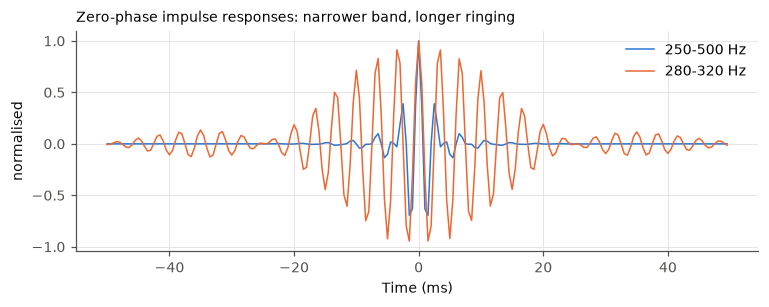

In [3]:
t = np.arange(-0.05, 0.05, 1 / FS)
impulse = np.zeros_like(t); impulse[len(t) // 2] = 1.0
fig, ax = plt.subplots(figsize=(8, 2.6))
for band, color in [((250.0, 500.0), plotting.SERIES[0]), ((280.0, 320.0), plotting.ACCENT)]:
    y = filters.bandpass(impulse, FS, band, params.filter_order)
    ax.plot(t * 1000, y / np.abs(y).max(), color=color, lw=1, label=f"{band[0]:.0f}-{band[1]:.0f} Hz")
ax.set_xlabel("Time (ms)"); ax.set_ylabel("normalised"); ax.legend()
ax.set_title("Zero-phase impulse responses: narrower band, longer ringing", loc="left");

## 3. Why a filtered spike looks like an HFO

All numbers below come from `results/false_hfo_demo.csv`.

In [4]:
demo = pd.read_csv(results / "false_hfo_demo.csv")
demo[["signal", "filter", "band_hz", "spectrum_300hz_rel", "peak_uv", "cycles_50pct", "cycles_10pct", "duration_2pct_ms", "cycles_2pct"]]

,signal,filter,band_hz,spectrum_300hz_rel,peak_uv,cycles_50pct,cycles_10pct,duration_2pct_ms,cycles_2pct
0,cusp spike (sharp apex),Butterworth N=4,250-500,1.241000e-02,26.080000,1.0,4.0,29.5,8.0
1,rounded spike (apex 1.35 ms),Butterworth N=4,250-500,4.873000e-04,1.103000,2.5,6.0,37.5,9.5
2,smooth Gaussian spike,Butterworth N=4,250-500,6.460000e-17,0.000057,1.0,3.0,37.5,3.0
3,"true fast ripple (300 Hz, 5 uV)",Butterworth N=4,250-500,1.000000e+00,4.424000,3.5,5.5,31.5,8.5
4,cusp spike (sharp apex),Butterworth N=4,250-350,NaN,14.380000,3.0,9.0,57.5,15.0
5,cusp spike (sharp apex),Butterworth N=4,280-320,NaN,5.632000,8.0,23.0,141.0,40.0
6,cusp spike (sharp apex),Butterworth N=4,295-305,NaN,1.403000,33.0,96.5,562.0,166.5
7,cusp spike (sharp apex),FIR 257 taps,250-500,NaN,24.740000,2.0,7.5,79.0,20.5


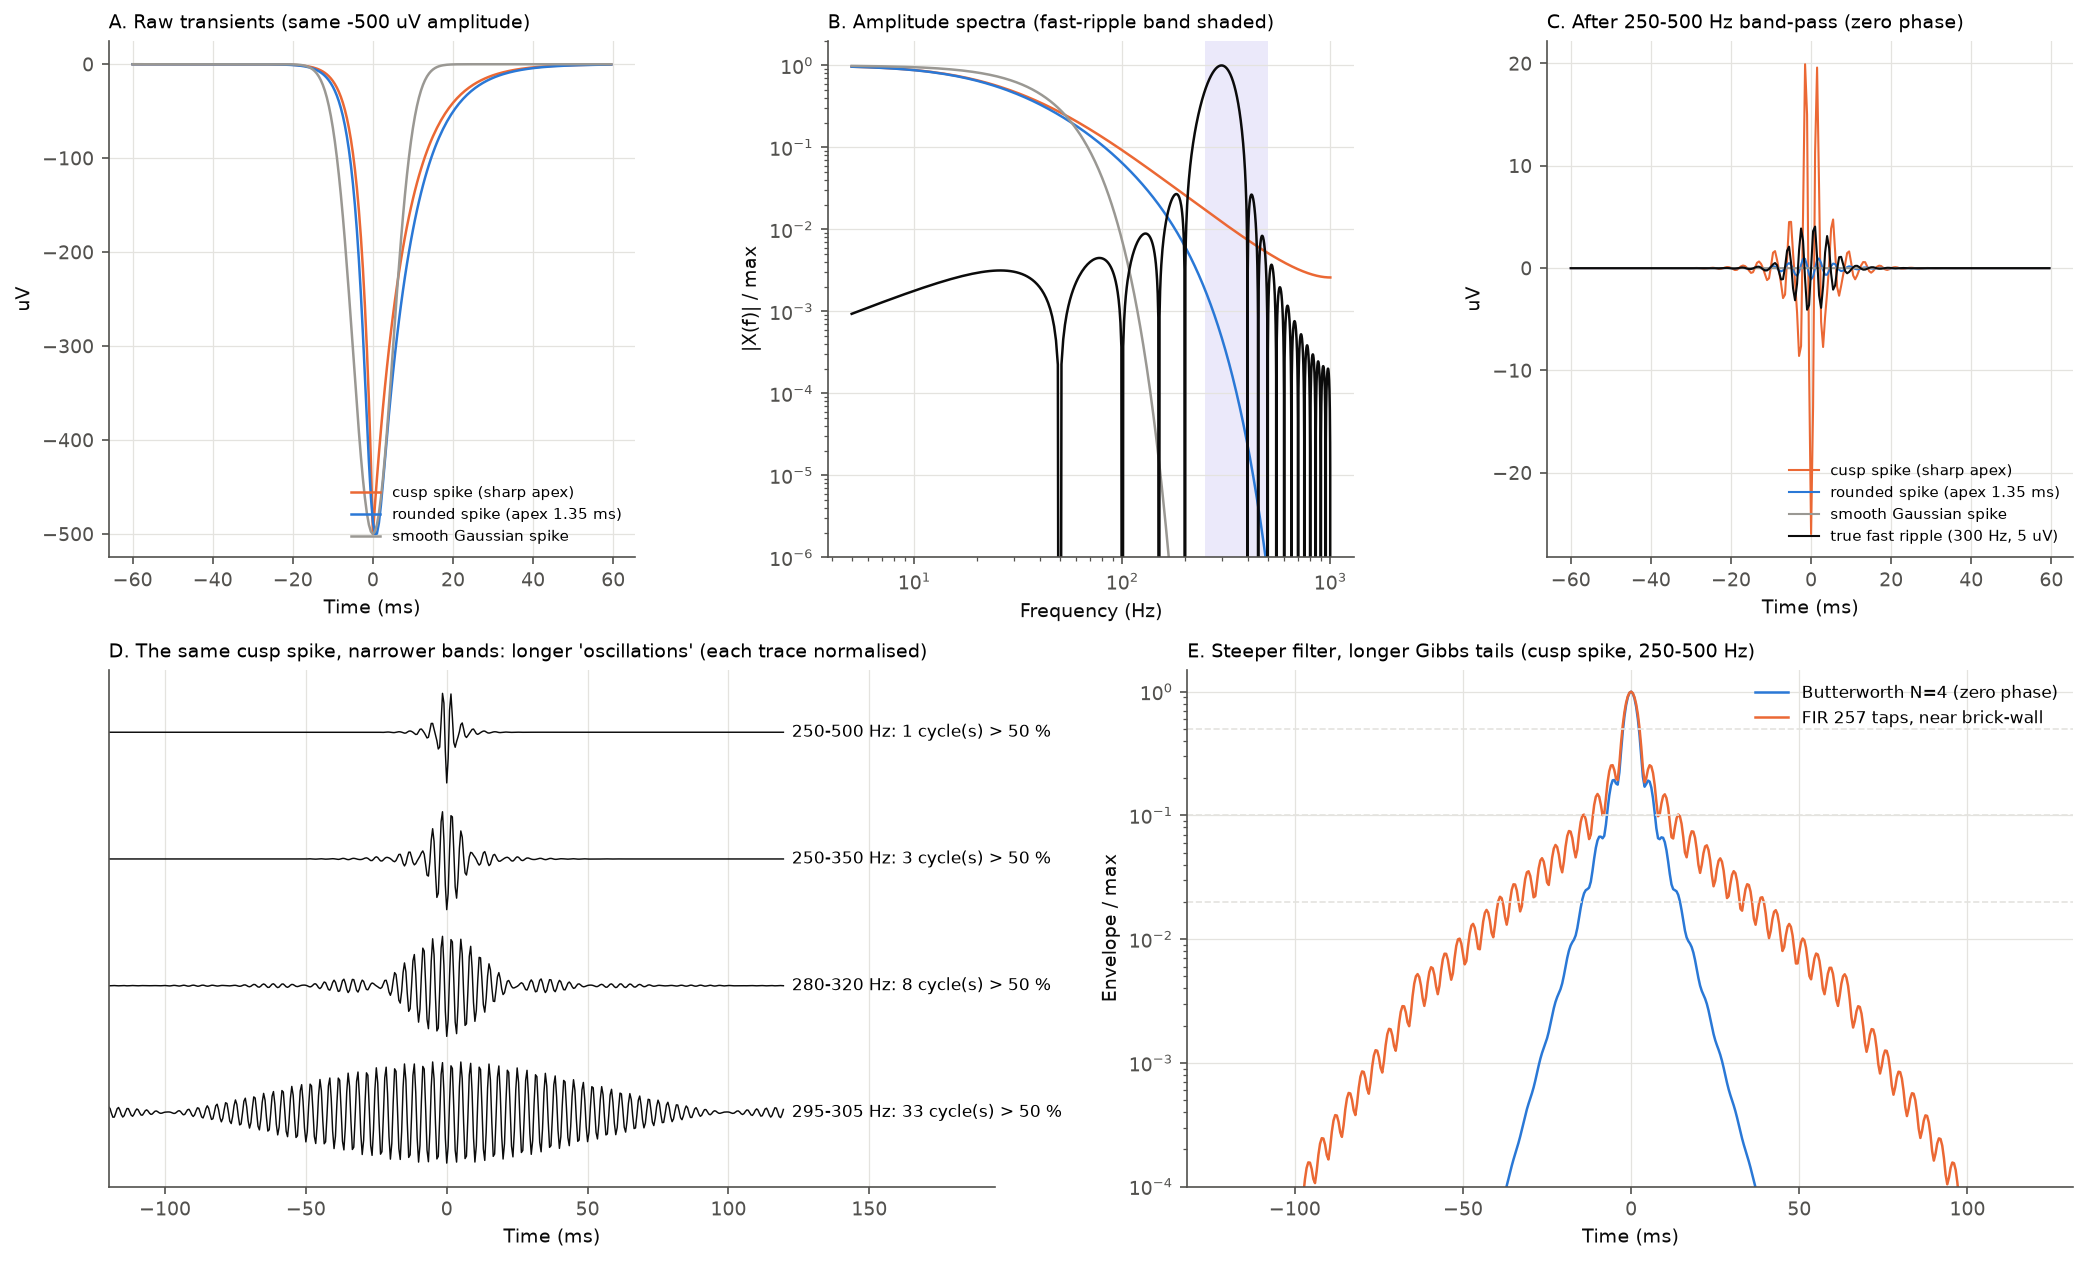

In [5]:
display(Image(filename=str(figures / "false_hfo_demo.png")))

Reading the table:

* The **cusp spike** (pure kink) has 1.2 % of its maximal spectral amplitude at 300 Hz; after filtering it gives a 26 uV burst, six times the 4.4 uV of a genuine 5 uV fast ripple.
* A **smooth Gaussian spike** of the same amplitude gives essentially nothing: the spectrum of a smooth function decays faster than any power of f. Sharpness, not amplitude, creates false HFOs.
* A spike with a **realistically rounded apex** (calibrated, see section 5) gives a ~1 uV burst lasting ~2-3 cycles: small, but comparable to genuine fast ripples near the noise floor.
* **Narrower bands** and **steeper filters** make the ringing last longer (more cycles): time-frequency uncertainty and Gibbs tails.

## 4. The simulated background

Spectrum `1/f^beta + floor` with a knee at 20 Hz, calibrated on the real channels (QC-flagged channels excluded).

In [6]:
pd.read_csv(results / "background_fit_summary.csv")

,quantity,value
0,n_channels,411.0000
1,fraction_floor_reached,0.6107
2,median_beta_floor_reached,3.4776
3,median_crossover_hz_floor_reached,260.4736
4,q25_crossover_hz_floor_reached,205.0643
5,q75_crossover_hz_floor_reached,322.1888
6,median_beta_all,3.5315
7,median_rmse_log10,0.1048


background fit on this simulation: {'beta': 3.46, 'crossover_hz': 266.841, 'floor': 0.001, 'rmse_log10': 0.063}


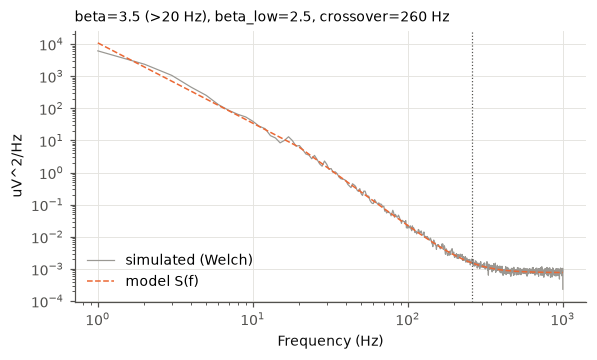

In [7]:
bg = params.background
x = bg.std_uv * simulate.colored_noise(int(60 * FS), FS, bg, np.random.default_rng(0))
freqs, psd = qc.welch_psd(x[None, :], FS)
model = simulate.background_psd_shape(freqs, bg)
model *= psd[0, (freqs > 20) & (freqs < 40)].mean() / model[(freqs > 20) & (freqs < 40)].mean()
fig, ax = plt.subplots(figsize=(6, 3.2))
keep = freqs >= 1
ax.loglog(freqs[keep], psd[0, keep], color=plotting.NEUTRAL, lw=0.8, label="simulated (Welch)")
ax.loglog(freqs[keep], model[keep], color=plotting.ACCENT, ls="--", label="model S(f)")
ax.axvline(bg.crossover_hz, color=plotting.INK_SECONDARY, lw=0.8, ls=":")
ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("uV^2/Hz"); ax.legend()
ax.set_title(f"beta={bg.beta} (>{bg.knee_hz:.0f} Hz), beta_low={bg.beta_low}, crossover={bg.crossover_hz:.0f} Hz", loc="left");
print("background fit on this simulation:", {k: round(v, 3) for k, v in simulate.fit_background_model(freqs, psd[0]).items()})

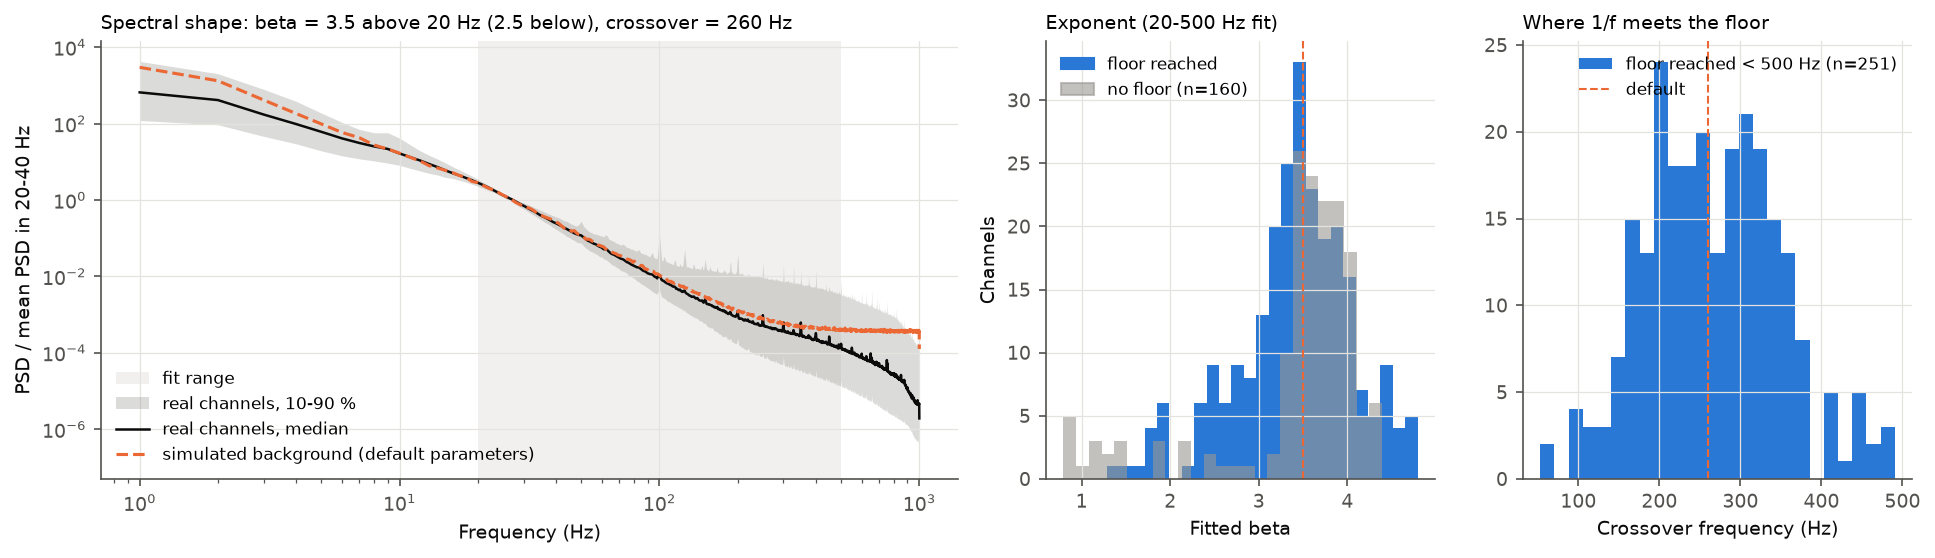

In [8]:
display(Image(filename=str(figures / "sim_background_calibration.png")))

## 5. Spike sharpness calibrated on real transients

Ringing ratio = max |250-500 Hz signal| within +/- 30 ms of a transient / robust std of that band. A pure cusp rings ~20 times too strongly; an apex rounded by a Gaussian of 1.1-1.6 ms matches the real distribution.

In [9]:
pd.read_csv(results / "spike_calibration_summary.csv", index_col=0).round(2)

,real,"simulated, pure cusp (apex 0 ms)","simulated, configured apex 1.1-1.6 ms"
q10,2.56,52.35,2.61
q25,3.10,67.11,3.41
q50,4.30,88.41,4.79
q75,6.92,119.14,7.02
q90,11.70,150.47,10.36


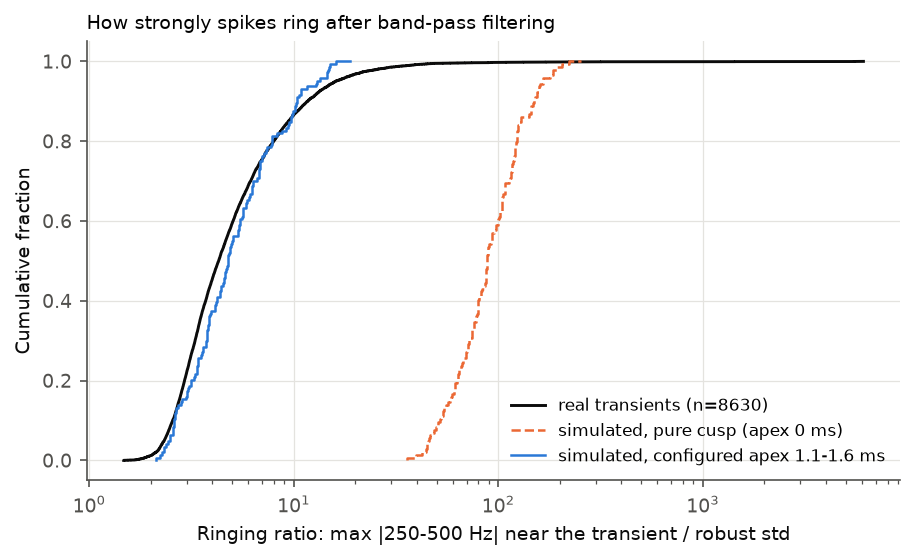

In [10]:
display(Image(filename=str(figures / "sim_spike_calibration.png")))

## 6. One simulation and its ground truth

In [11]:
sim = simulate.simulate_from_seed(params, cfg["simulation"]["seed"])
print(f"{params.duration_s:.0f} s, {len(sim.events)} events")
print(sim.events.groupby(["kind", "on_spike"]).size().to_string())
sim.events.head(8).round(3)

60 s, 14 events
kind         on_spike
fast_ripple  False       3
ripple       False       2
             True        1
spike        False       8


,event_id,kind,on_spike,center_s,onset_s,offset_s,duration_s,freq_hz,n_cycles,amplitude_uv,snr_db,spike_amplitude_uv
0,0,ripple,True,6.018,5.985,6.052,0.067,136.052,9.105,8.665,10.0,624.201
1,1,spike,False,14.120,14.109,14.141,0.032,NaN,NaN,NaN,NaN,-860.741
2,2,spike,False,18.087,18.084,18.107,0.024,NaN,NaN,NaN,NaN,565.143
3,3,spike,False,23.730,23.725,23.752,0.028,NaN,NaN,NaN,NaN,489.493
4,4,spike,False,33.271,33.264,33.304,0.039,NaN,NaN,NaN,NaN,-814.445
5,5,fast_ripple,False,35.419,35.408,35.430,0.021,364.997,7.728,3.619,10.0,NaN
6,6,ripple,False,37.566,37.548,37.584,0.037,120.362,4.452,8.687,10.0,NaN
7,7,fast_ripple,False,41.582,41.572,41.591,0.019,407.091,7.871,3.607,10.0,NaN


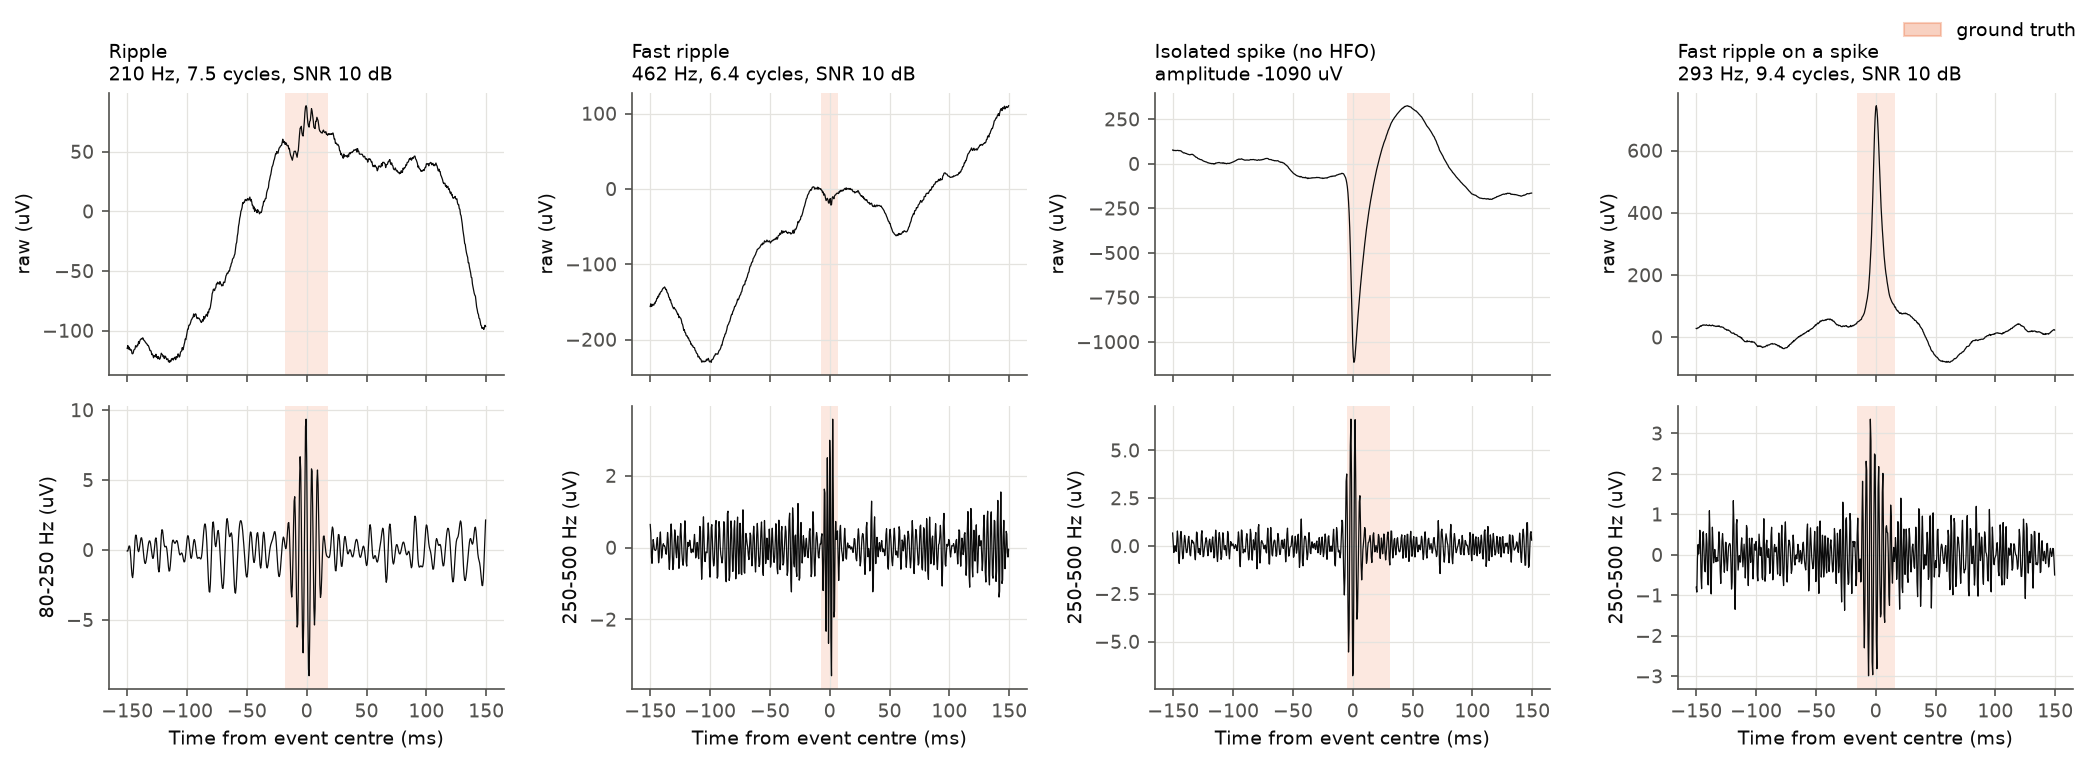

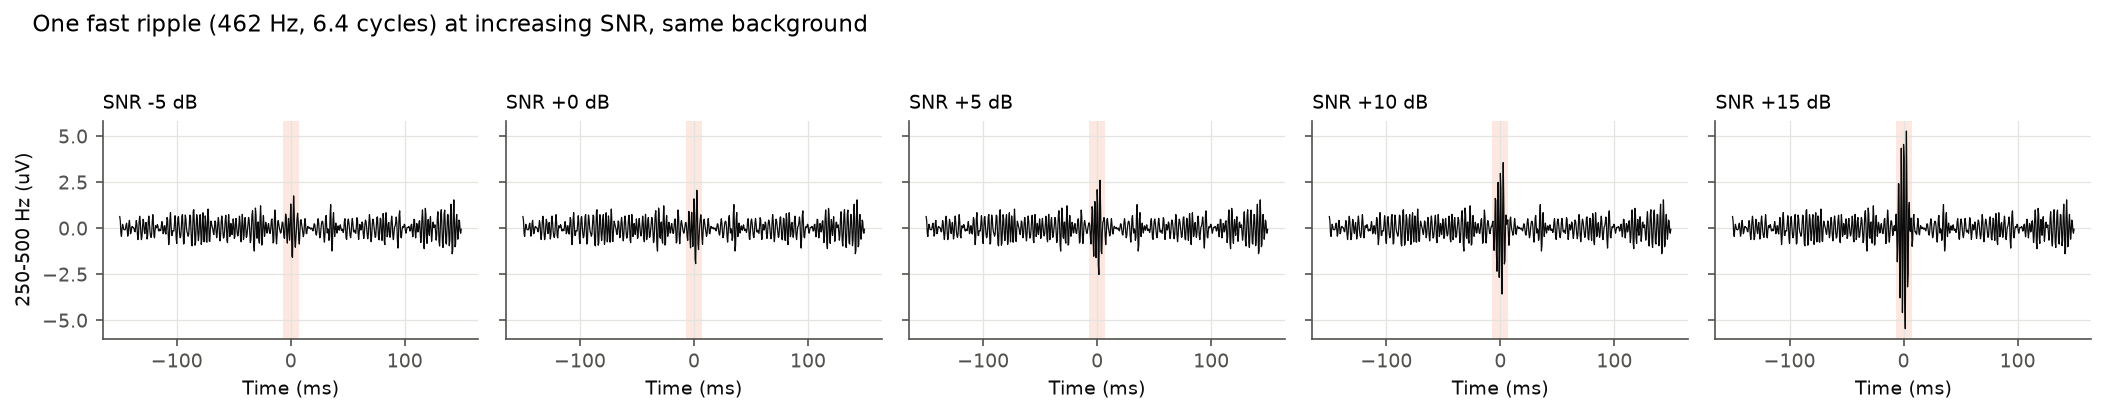

In [12]:
for name in ["sim_examples", "sim_snr_levels"]:
    display(Image(filename=str(figures / f"{name}.png")))

## 7. Take-aways

* `filtfilt` gives zero phase (no shift of events) but squares the gain: -6 dB at the cut-offs.
* A band-pass filter's impulse response *is* a short oscillation: a sharp transient becomes a false HFO.
* The strength of that effect depends on the spike's apex sharpness, calibrated here on real transients.
* The simulator reproduces the real spectral shape between ~8 and 500 Hz; above 500 Hz the real anti-aliasing roll-off is not modelled (outside the HFO bands).
* SNR is defined in each event's band, so 0 dB means the event has the power of the background *in its own band*.